Author: Adam Gawęda

In [61]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import math

Firstly, let's see how does simple ranking algorithm work:

In [62]:
def simple_rank(A, max_iter=1000):
    n = A.shape[0]
    w = np.ones(n)/n
    v = A @ w
    for _ in range (max_iter):
        s = np.sum(v)
        if s>0:
            v = v/s
        else:
            v= np.ones(n)/n
        if (np.linalg.norm(w-v) <= 1e-10):
            break
        w = v
        v = A @ w
    return v

In 1996 Larry Page with Sergery Bin invented new algorithm for node ranking, then it formed Google Search we know. It's updated simple_rank by using "teleports" - probability that man can go for an unrelated site after some time.

In [63]:
def pagerank(A, d, max_iter=1000):
    n = A.shape[0]
    w = np.ones(n)/n
    history = []
    for i in range(max_iter):
        w_new = d * A.dot(w) + (1-d) * np.ones(n)/n
        difference = np.linalg.norm(w_new - w, 1)
        if difference < 1e-10:
            w = w_new
            break
        history.append(difference)
        w = w_new
    return w, history

Let's make helpful functions, that will make testing easier

In [64]:
def generate_graph(n, p=0.3):
    graph = [[] for _ in range (n)]

    for u in range (n):
        for v in range (n):
            if u!=v and np.random.random() < p:
                graph[u].append(v)
    return graph

def make_matrix(graph):
    n = len(graph)
    A = np.zeros((n,n))

    for u in range (n):
        vertex = graph[u]
        normalize = len(vertex)
        if normalize>0:
            for v in vertex:
                A[v,u]=1/normalize
    return A

Now let's visualize it

In [65]:
def visualize_pagerank_comprehensive(G, pr_scores, history, d_val, pr_multi_d, k=5):
    """
    Kompleksowa wizualizacja wyników PageRank dla Jupyter Notebook.
    G: obiekt networkx.DiGraph
    pr_scores: tablica/lista wartości PageRank dla głównego d
    history: lista wartości delta z kolejnych iteracji
    d_val: główna wartość parametru tłumienia
    pr_multi_d: słownik {d: wektor_pr} do wykresu top-k
    k: liczba wierzchołków top-k
    """
    # Ustawienia stylu dla Jupyter Notebook
    plt.rcParams['figure.figsize'] = (16, 24)
    fig = plt.figure(constrained_layout=True)
    gs = fig.add_gridspec(3, 2)

    # 1. Rysunek grafu (wielkość i kolor wg PageRank)
    ax1 = fig.add_subplot(gs[0, :])
    pos = nx.spring_layout(G, seed=42)
    node_sizes = [pr_scores[node] * 10000 for node in G.nodes()]
    nodes = nx.draw_networkx_nodes(G, pos, ax=ax1, node_size=node_sizes,
                                   node_color=pr_scores, cmap=plt.cm.plasma, alpha=0.9)
    nx.draw_networkx_edges(G, pos, ax=ax1, alpha=0.3, arrowsize=10)
    fig.colorbar(nodes, ax=ax1, label="PageRank Score")
    ax1.set_title("Graf ze skalowaniem wierzchołków (rozmiar i kolor proportionalne do PR)")
    ax1.axis("off")

    # 2. Krzywa zbieżności w skali półlogarytmicznej
    ax2 = fig.add_subplot(gs[1, 0])
    iterations = np.arange(1, len(history) + 1)
    ax2.semilogy(iterations, history, 'bo-', label=r'$\delta_i$ (eksperymentalnie)')

    # Teoretyczne nachylenie: log d
    theoretical = [history[0] * (d_val ** i) for i in range(len(history))]
    ax2.semilogy(iterations, theoretical, 'r--', label=r'Teoretyczne nachylenie ($d^i$)')

    ax2.set_xlabel("Iteracja")
    ax2.set_ylabel(r"$\delta_i = ||r_{i+1} - r_i||_1$")
    ax2.set_title(f"Krzywa zbieżności (skala półlogarytmiczna, d={d_val})")
    ax2.grid(True, which="both", ls="--", alpha=0.5)
    ax2.legend()

    # 3. Histogram wartości PageRank (skala logarytmiczna dla osi Y)
    ax3 = fig.add_subplot(gs[1, 1])
    ax3.hist(pr_scores, bins=20, color='teal', edgecolor='black', log=True)
    ax3.set_xlabel("Wartość PageRank")
    ax3.set_ylabel("Częstość (skala logarytmiczna)")
    ax3.set_title("Histogram wartości PageRank (ciężki ogon)")
    ax3.grid(axis='y', ls="--", alpha=0.7)

    # 4. Wykres rozrzutu PR vs Stopień wejściowy (log-log)
    ax4 = fig.add_subplot(gs[2, 0])
    in_degrees = [G.in_degree(n) for n in G.nodes()]
    # Dodajemy małą wartość (1e-5), aby uniknąć log(0) dla wierzchołków bez krawędzi wejściowych
    ax4.scatter(np.array(in_degrees) + 1e-5, pr_scores, color='purple', alpha=0.7)
    ax4.set_xscale('log')
    ax4.set_yscale('log')
    ax4.set_xlabel(r"Stopień wejściowy $|B_u|$")
    ax4.set_ylabel("PageRank")
    ax4.set_title("Wykres rozrzutu: PageRank vs Stopień wejściowy (log-log)")
    ax4.grid(True, which="both", ls="--", alpha=0.5)

    # 5. Wykres słupkowy top-k wierzchołków dla różnych d
    ax5 = fig.add_subplot(gs[2, 1])
    # Wybieramy top-k wierzchołków na podstawie bazowego d_val
    top_k_indices = np.argsort(pr_scores)[-k:][::-1]

    d_keys = list(pr_multi_d.keys())
    bar_width = 0.8 / len(d_keys)
    x = np.arange(k)

    for idx, d_param in enumerate(d_keys):
        scores = [pr_multi_d[d_param][i] for i in top_k_indices]
        ax5.bar(x + idx * bar_width - 0.4 + bar_width / 2, scores, bar_width, label=f'd={d_param}')

    ax5.set_xticks(x)
    ax5.set_xticklabels([f"Węzeł {i}" for i in top_k_indices])
    ax5.set_xlabel("Wierzchołki (top-k)")
    ax5.set_ylabel("PageRank")
    ax5.set_title("Wrażliwość rankingu na parametr d (Top-K wierzchołków)")
    ax5.legend()
    ax5.grid(axis='y', ls="--", alpha=0.7)

    plt.show()

Code for using Visualize_pagerank_comprehensive

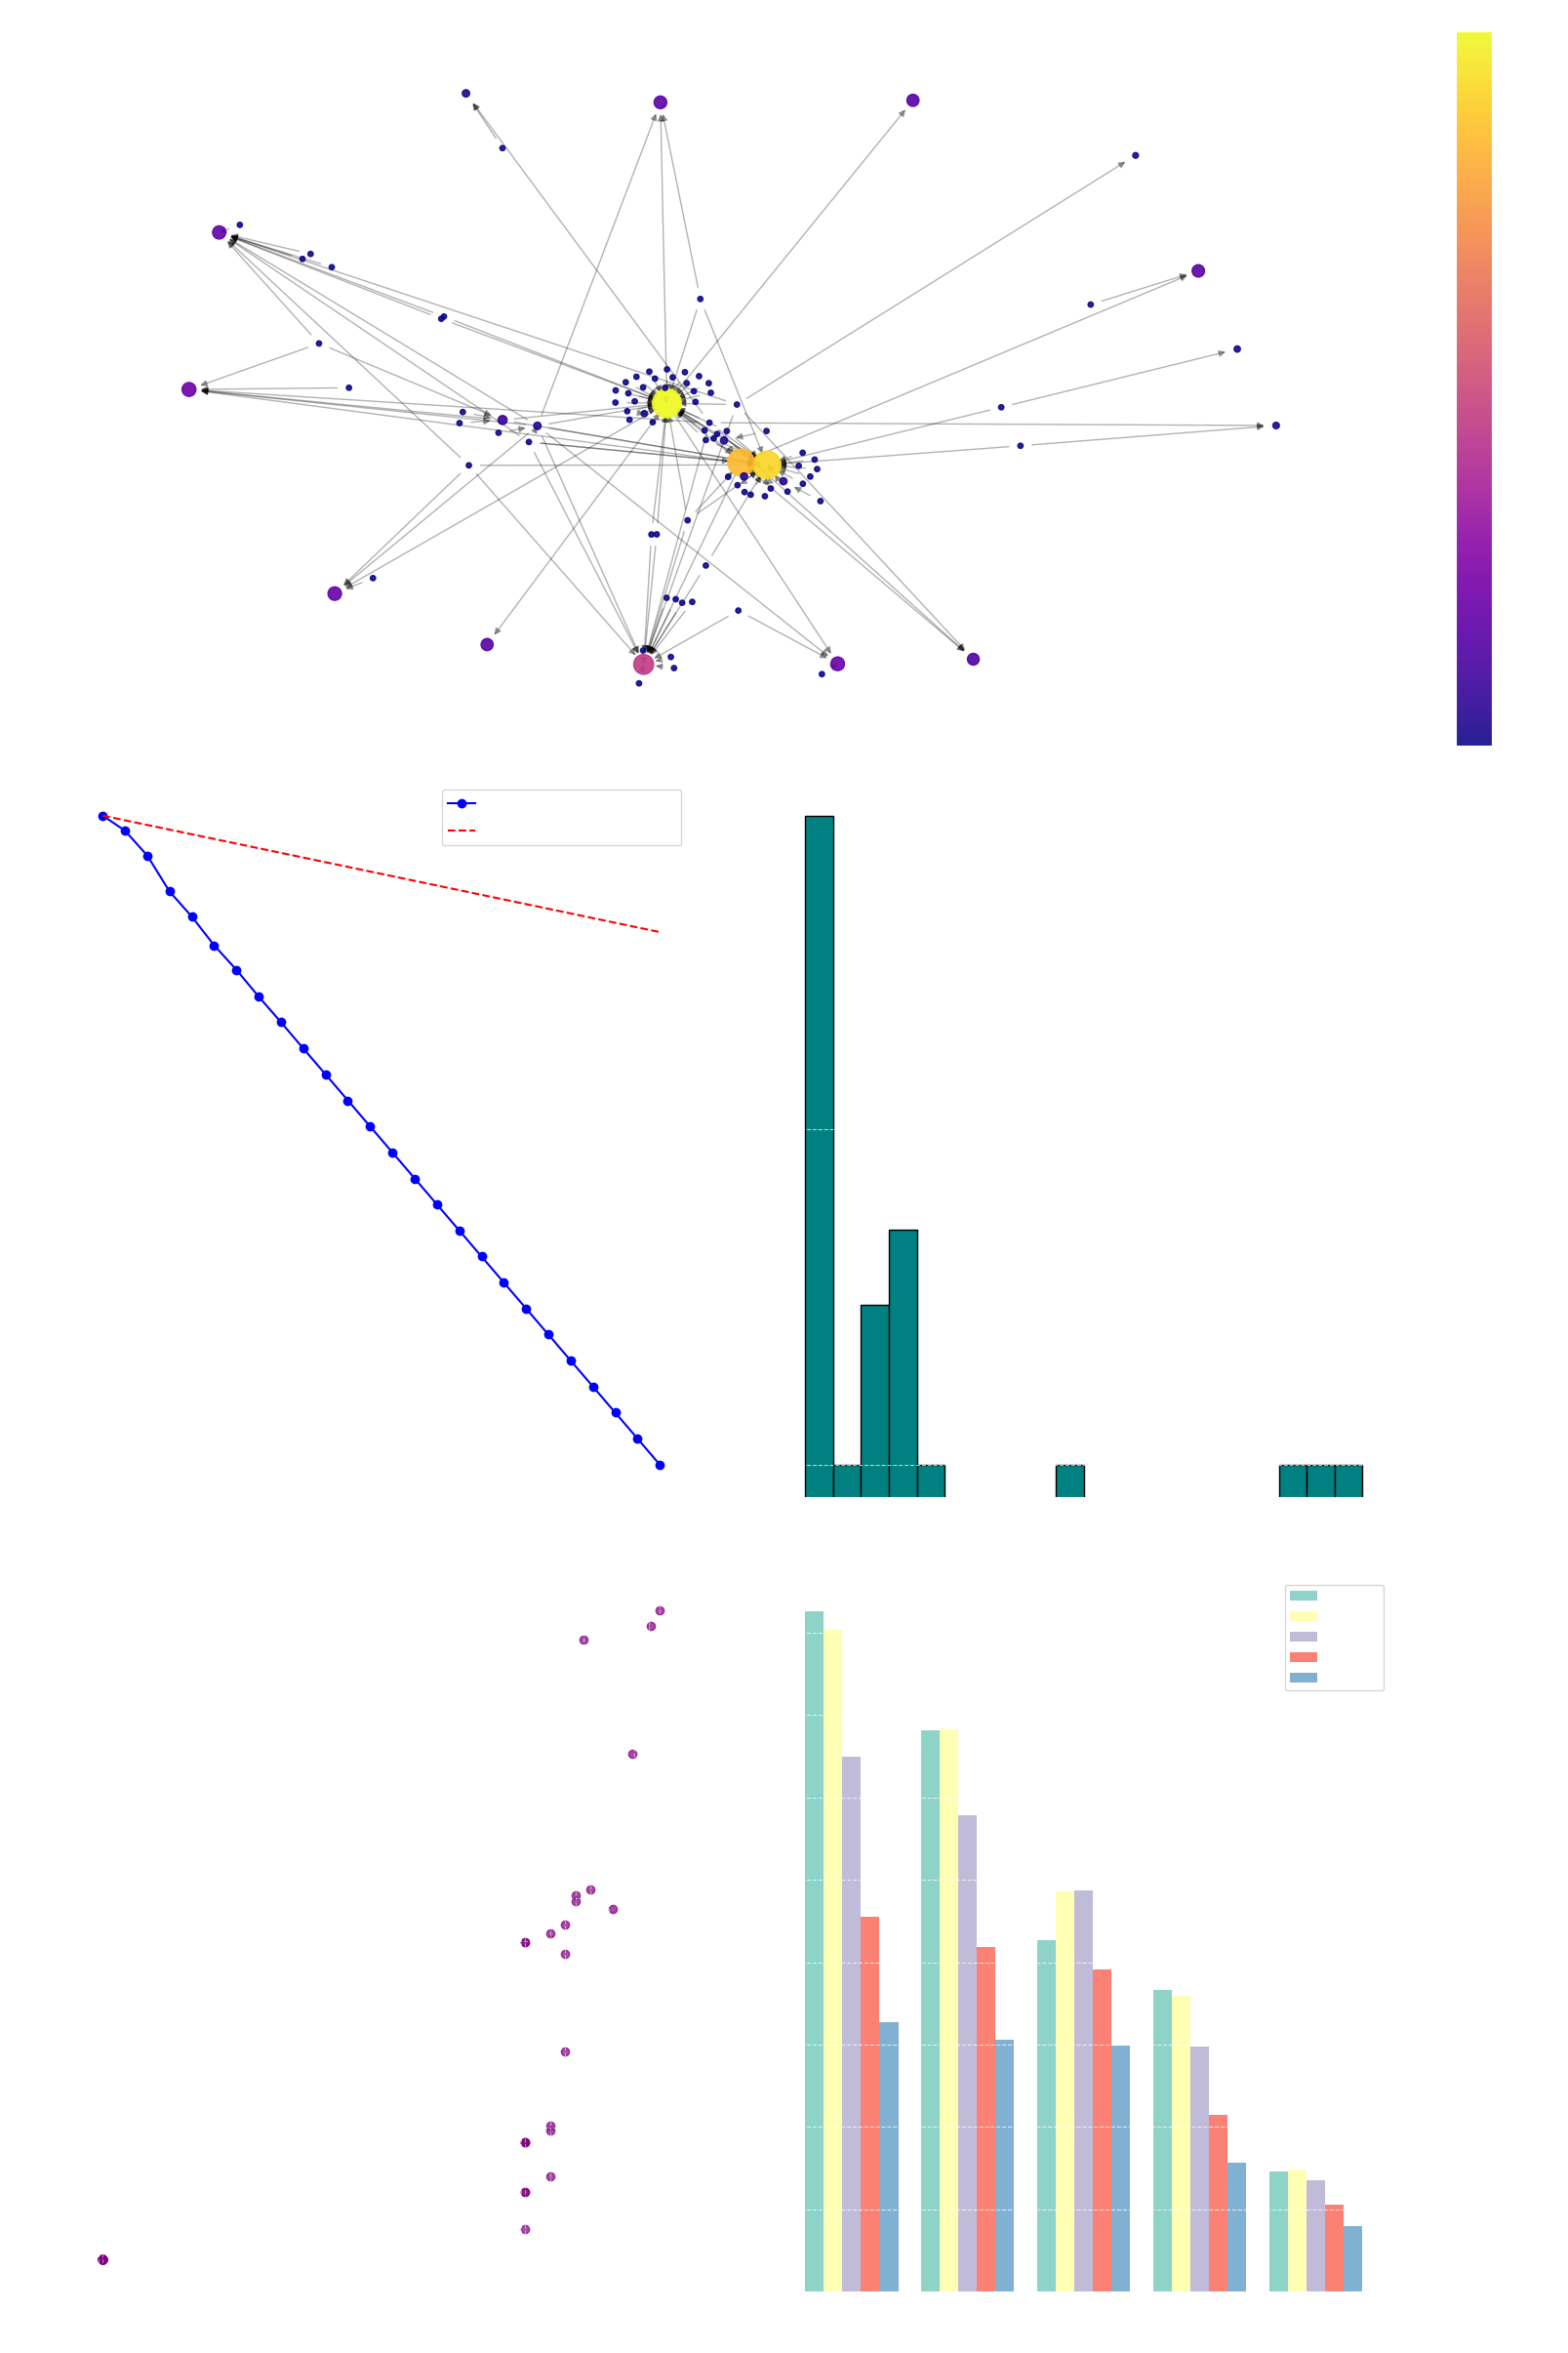

In [66]:
n_nodes = 100
G_multi = nx.scale_free_graph(n_nodes, seed=42)
G = nx.DiGraph(G_multi)
G.remove_edges_from(nx.selfloop_edges(G))

A = make_matrix(G)

base_d = 0.85
pr_scores, history = pagerank(A, d=base_d)

d_values = [0.5, 0.6, 0.75, 0.85, 0.9]
pr_multi_d = {}

for d_val in d_values:
    pr_scores_d, _ = pagerank(A, d=d_val)
    pr_multi_d[d_val] = pr_scores_d

visualize_pagerank_comprehensive(
    G=G,
    pr_scores=pr_scores,
    history=history,
    d_val=base_d,
    pr_multi_d=pr_multi_d,
    k=5
)

Once again, now using other generating method

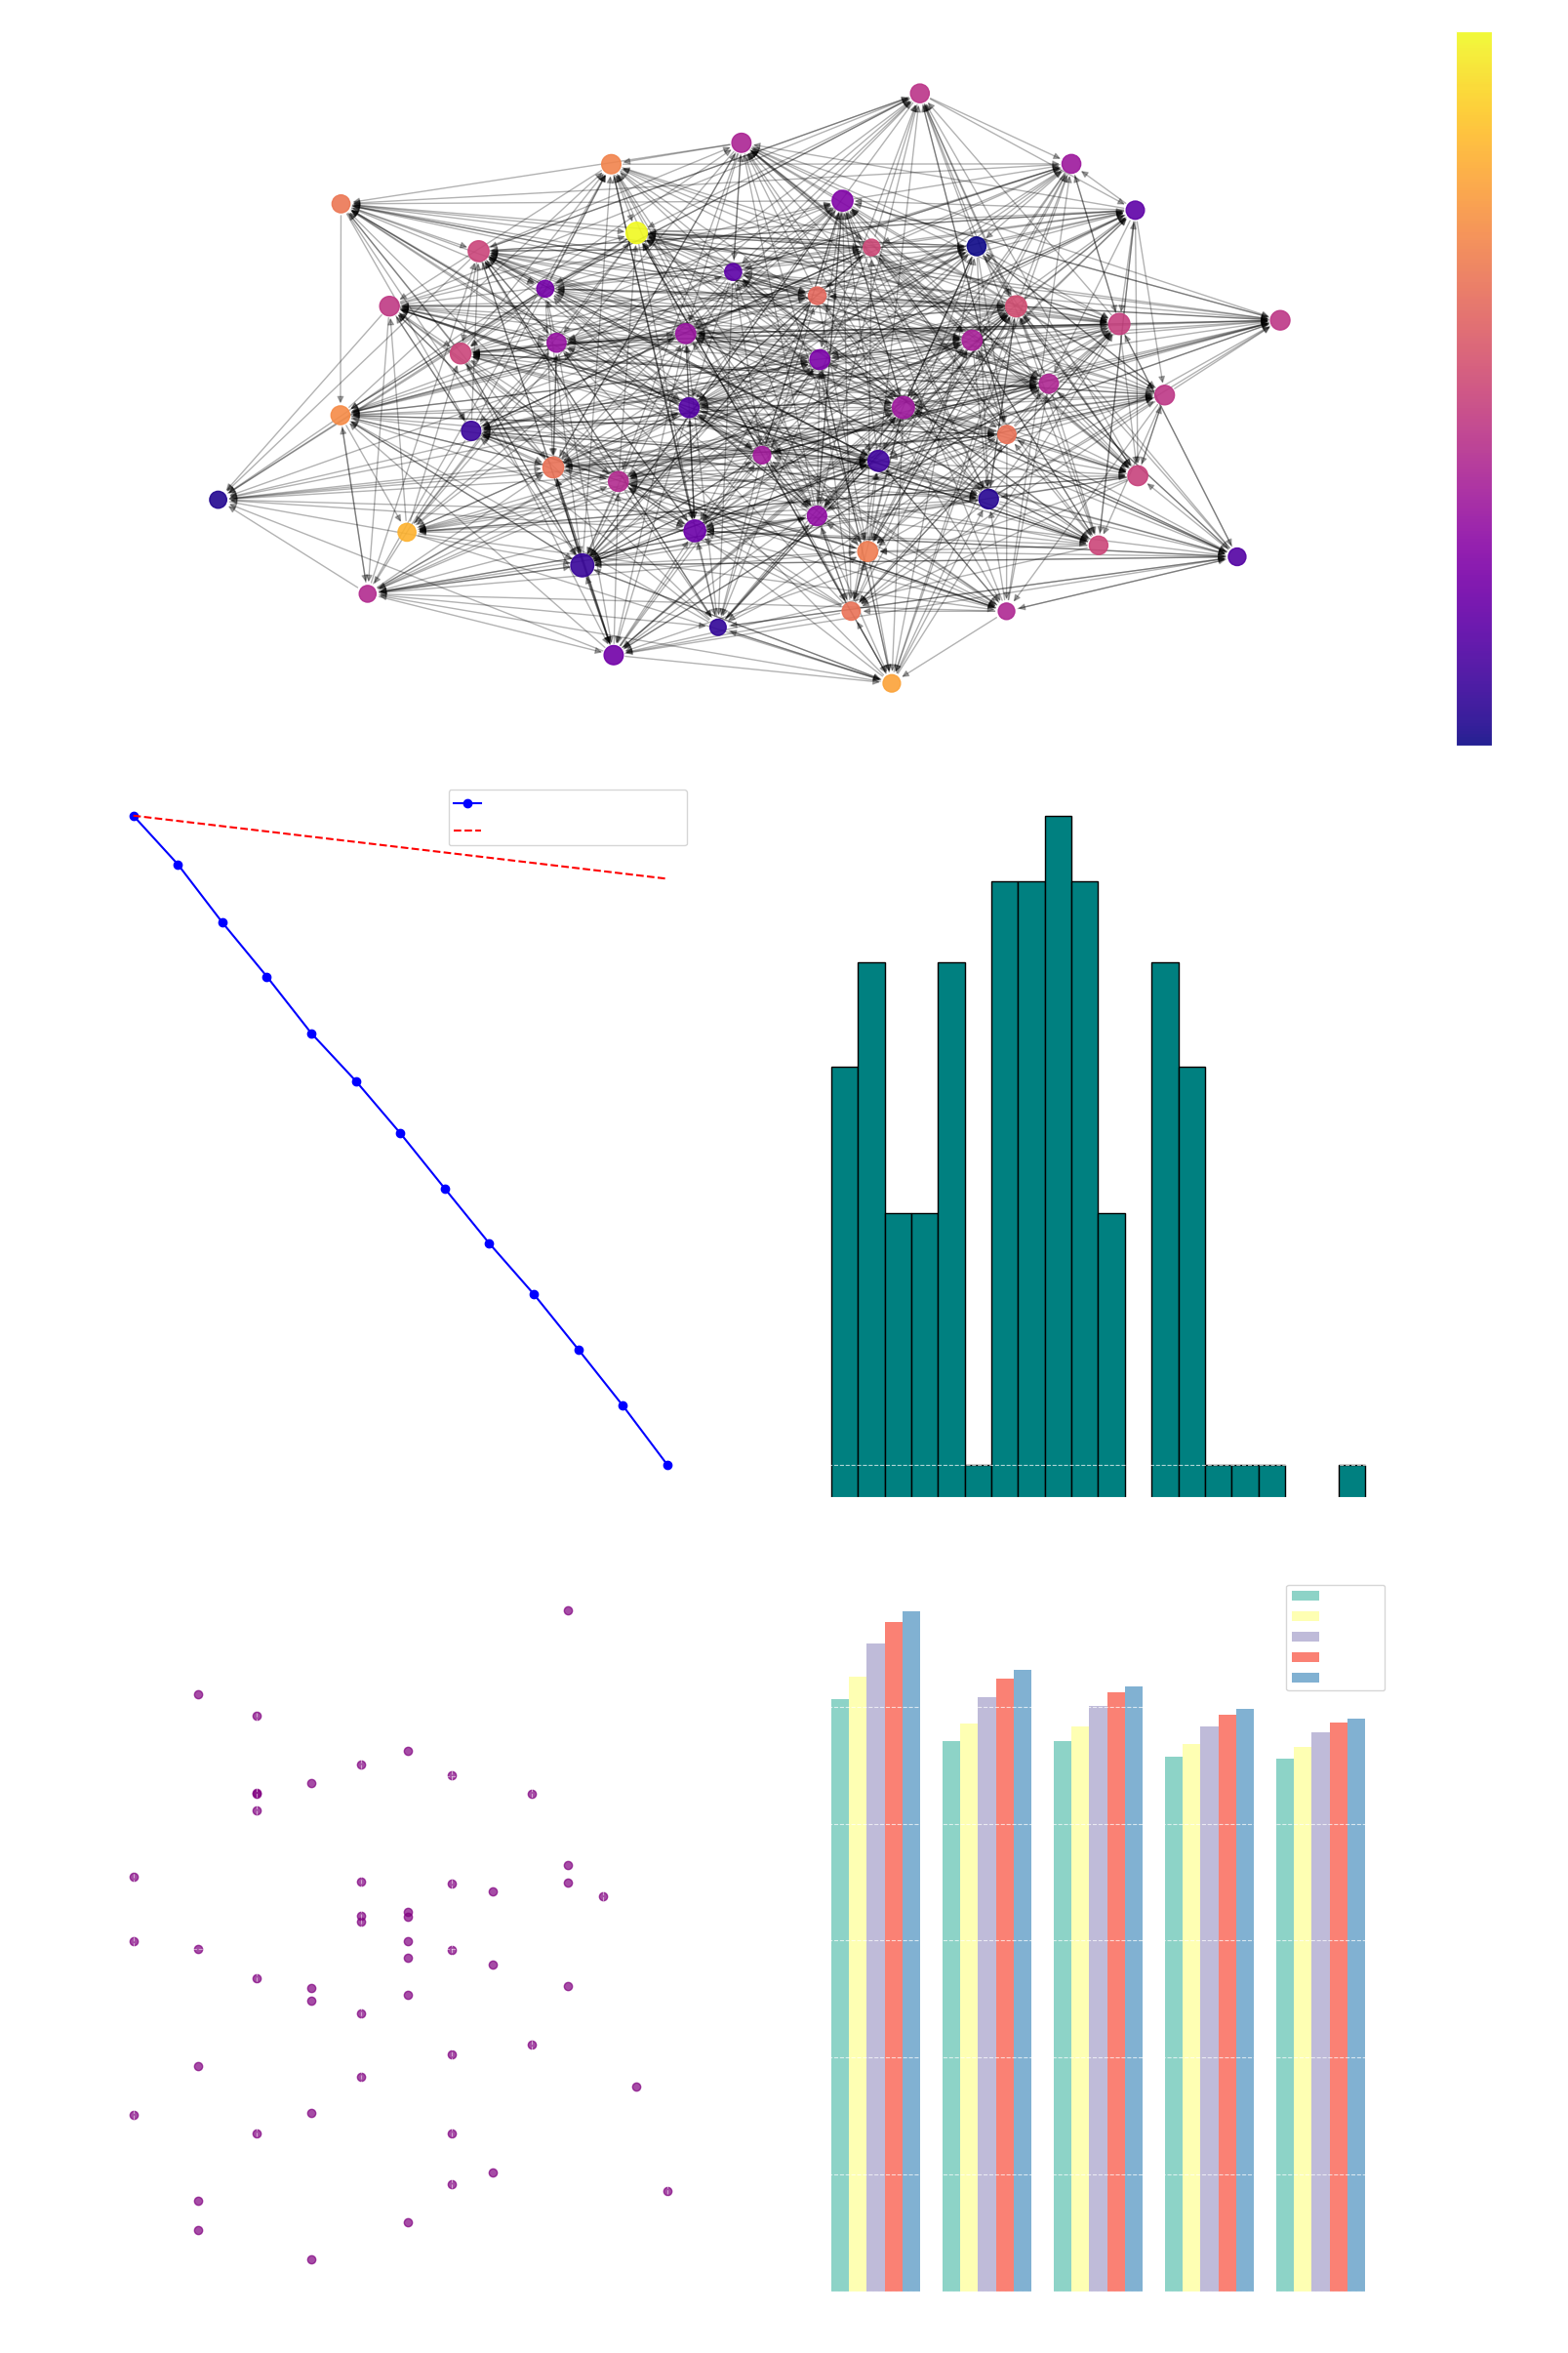

In [67]:
n_nodes = 50
G_my = generate_graph(n_nodes)
G = nx.DiGraph()
for u in range(len(G_my)):
    for v in G_my[u]:
        G.add_edge(u, v)

A = make_matrix(G)

base_d = 0.85
pr_scores, history = pagerank(A, d=base_d)

d_values = [0.5, 0.6, 0.75, 0.85, 0.9]
pr_multi_d = {}

for d_val in d_values:
    pr_scores_d, _ = pagerank(A, d=d_val)
    pr_multi_d[d_val] = pr_scores_d

visualize_pagerank_comprehensive(
    G=G,
    pr_scores=pr_scores,
    history=history,
    d_val=base_d,
    pr_multi_d=pr_multi_d,
    k=5
)